# MSNBC Web Navigation Analysis via k Order Markov Chains

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ParthamSolanki/markov_web_navigation/blob/main/Markov_Model_(Term_Paper).ipynb)

This notebook implements up to $6^{th}$ order Markov chains along with threshold pruning to compare them against each other. 

# Importing dependencies & defining constant

- Importing needed libraries.
- Making ranomization uniform so the results can be replicated.
- Defining constants

In [1]:
# Importing dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict, Counter
import random
import math
import urllib.request
import gzip
import zipfile
from pathlib import Path

# Setting random seed for output reproducability
random.seed(42)

# Setting up default paths
DATA_DIR = Path("data")
SEQ_FILE = DATA_DIR / "msnbc990928.seq"
SOURCE_URL = "https://archive.ics.uci.edu/static/public/133/msnbc+com+anonymous+web+data.zip"

K_VALUES = [1, 2, 3, 4, 5, 6]
TAU_VALUES = [0, 5, 10]
NUM_STATES = 17
ALPHA = 1.0

CATEGORIES = [
    "frontpage", "news", "tech", "local", "opinion", "on-air", "misc",
    "weather", "health", "living", "business", "sports", "summary",
    "bbs", "travel", "msn-news", "msn-sports"
]

# Ensuring the dataset exists otherwise downloading it

In [2]:
# This function checks if the dataset exists locally otherwise it downloads it for usage.
def ensure_msnbc_dataset(url = SOURCE_URL, file_path = SEQ_FILE):
    if file_path.exists():
        print(f"Dataset exists at -'{file_path}'")
        return
    file_path.parent.mkdir(parents=True, exist_ok=True)
    zip_path = file_path.parent / "msnbc.zip"
    print(f"Dataset not found at location '{file_path}'. Downloading...")
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})

    with urllib.request.urlopen(req) as response, open(zip_path, 'wb') as out_file:
        out_file.write(response.read())

    with zipfile.ZipFile(zip_path, 'r') as z:
        # Extract the .seq file directly into the data folder
        gz_file = next(f for f in z.namelist() if f.endswith('seq.gz') or f.endswith('.seq'))
        gz_data = z.read(gz_file)

    if gz_file.endswith('.gz'):
        raw_seq = gzip.decompress(gz_data)
    else:
        raw_seq = gz_data

    with open(file_path, 'wb') as f:
        f.write(raw_seq)

    if zip_path.exists():
        zip_path.unlink()

    print(f"Dataset successfully downloaded to - '{file_path}'.")

# Loading dataset for usage

In [3]:
def load_msnbc_sequences(file_path=SEQ_FILE):
    sequences = []
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('%'):
                continue
            seq = [int(x) for x in line.split() if x.isdigit()]
            if seq:
                sequences.append(seq)
    return sequences

# Function to build the Markov chain

In [4]:
# This function builds the k-order Markov Model transition tables.
# Also prunes history contexts observed fewer than tau times optionally if value passed.
def build_markov_model(
    sequences,
    k,
    tau = 0
):
    transitions = defaultdict(Counter)

    for seq in sequences:
        if len(seq) <= k:
            continue
        for i in range(len(seq) - k):
            history = tuple(seq[i:(i + k)])
            next_state = seq[i + k]
            transitions[history][next_state] += 1

    if tau > 0:
        return {h: counts for h, counts in transitions.items() if sum(counts.values()) >= tau}

    return dict(transitions)
# Converting to dict before returning as due to defualt dict if you access a non existing key it creates one on the fly which is not ideal.
# Like a["Hello"] even if doesn't exist in the source seq file it would be created on the fly with an empty counter causing issues.

# Function to process the dataset & calculate the metrics for benchmarking & comparison

In [5]:
# Calculating & returning the benchmarking metrics after using Laplace smoothing.
def predict_and_evaluate(
    model, 
    test_sequences, 
    k, 
    alpha = 1.0, 
    num_states = 17
):
    total_log_likelihood = 0.0
    correct_predictions = 0
    total_predictions = 0

    for seq in test_sequences:
        if len(seq) <= k:
            continue

        for i in range(len(seq) - k):
            history = tuple(seq[i:i + k])
            actual_next = seq[i + k]

            counts = model.get(history, Counter())
            total_observations = sum(counts.values())
            denominator = total_observations + (alpha * num_states)

# Top 1 prediction, with a fallback if the data doesn't exists, so it doesn't throw error.
            if total_observations == 0:
                best_state = random.randint(1, num_states)
            else:
                best_state = max(
                    range(1, num_states + 1),
                    key=lambda s: counts.get(s, 0)
                )

            if best_state == actual_next:
                correct_predictions += 1

# log-likelihood for the observed state
            actual_prob = (counts.get(actual_next, 0) + alpha) / denominator
            total_log_likelihood += math.log(actual_prob)
            total_predictions += 1

    if total_predictions == 0:
        return 0.0, 0.0

    avg_log_likelihood = total_log_likelihood / total_predictions
    accuracy = correct_predictions / total_predictions

    return avg_log_likelihood, accuracy

# Splitting data for training & testing

In [6]:
ensure_msnbc_dataset()
data = load_msnbc_sequences()
random.shuffle(data)
split_idx = int(len(data) * 0.8)
train_data = data[:split_idx]
test_data = data[split_idx:]
print(f"Total sequences: {len(data)}, Train: {len(train_data)}, Test: {len(test_data)}")

Dataset exists at -'data\msnbc990928.seq'
Total sequences: 989818, Train: 791854, Test: 197964


# Calculating metrics for various order Markov models with various pruning thresholds

In [10]:
results = []

print(f"Running search over orders k={K_VALUES} and pruning thresholds tau={TAU_VALUES}...")

for k in K_VALUES:
    for tau in TAU_VALUES:
# Build Markov model on training sequences
        model = build_markov_model(train_data, k=k, tau=tau)
        
# Evaluate model and get metrics for benchmarking & comparison with other models.
        avg_ll, acc = predict_and_evaluate(
            model=model,
            test_sequences=test_data,
            k=k,
            alpha=ALPHA,
            num_states=NUM_STATES
        )
        
        results.append({
            'Order (k)': k,
            'Threshold (tau)': tau,
            'Active States': len(model),
            'Max Theoretical States': NUM_STATES ** k,
            'Accuracy': acc,
            'Avg Log-Likelihood': avg_ll
        })

df_results = pd.DataFrame(results)

print()
print("Table : Markov Chain Performance & State-Space Expansion")
print()

# Rounding the decimals to limit to certain digits after it
df_results['Accuracy'] = df_results['Accuracy'].round(4)
df_results['Avg Log-Likelihood'] = df_results['Avg Log-Likelihood'].round(4)
df_results.style.hide() # To hide the index

Running search over orders k=[1, 2, 3, 4, 5, 6] and pruning thresholds tau=[0, 5, 10]...

Table : Markov Chain Performance & State-Space Expansion



Order (k),Threshold (tau),Active States,Max Theoretical States,Accuracy,Avg Log-Likelihood
1,0,17,17,0.661100,-1.358300
1,5,17,17,0.661100,-1.358300
1,10,17,17,0.661100,-1.358300
2,0,289,289,0.696000,-1.141700
2,5,286,289,0.696000,-1.141700
2,10,281,289,0.695900,-1.141700
3,0,4164,4913,0.710600,-1.064300
3,5,3336,4913,0.710400,-1.064500
3,10,2892,4913,0.709900,-1.065100
4,0,30980,83521,0.717200,-1.048600


# Vizualizations

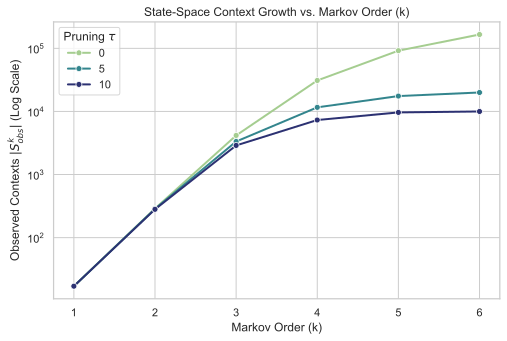

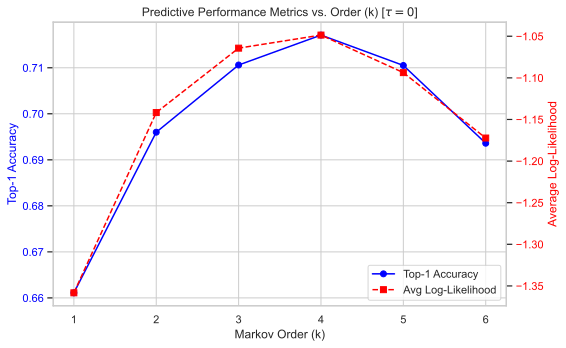

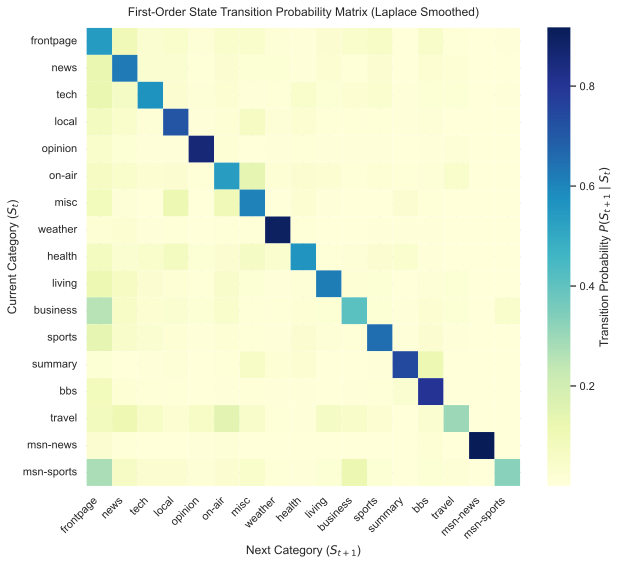

In [8]:
# Use this to get svg output which is crisp everywhere.
%config InlineBackend.figure_format = 'svg'

sns.set_theme(style="whitegrid", font="sans-serif")

# State-Space Expansion Plot (Active States vs. Order (k))
plt.figure(figsize=(8, 5))
ax = sns.lineplot(
    data=df_results, 
    x='Order (k)', 
    y='Active States', 
    hue='Threshold (tau)', 
    marker='o', 
    palette='crest',
    linewidth=2
)
plt.yscale('log')
plt.title('State-Space Context Growth vs. Markov Order (k)')
plt.xlabel('Markov Order (k)')
plt.ylabel('Observed Contexts $|S^k_{obs}|$ (Log Scale)')
plt.xticks(K_VALUES)
plt.legend(title=r'Pruning $\tau$', frameon=True)

plt.show()


# Accuracy & Log-Likelihood
fig, ax_acc = plt.subplots(figsize=(8, 5))
df_unpruned = df_results[df_results['Threshold (tau)'] == 0]

# Primary axis: Accuracy
line1 = ax_acc.plot(
    df_unpruned['Order (k)'], 
    df_unpruned['Accuracy'], 
    color="blue", 
    marker='o',  
    label='Top-1 Accuracy'
)
ax_acc.set_xlabel('Markov Order (k)')
ax_acc.set_ylabel('Top-1 Accuracy', color="blue")
ax_acc.tick_params(axis="y", labelcolor="blue")
ax_acc.set_xticks(K_VALUES)

# Secondary axis: Avg Log-Likelihood
ax_ll = ax_acc.twinx()
line2 = ax_ll.plot(
    df_unpruned['Order (k)'], 
    df_unpruned['Avg Log-Likelihood'], 
    color="red", 
    marker='s', 
    linestyle='--', 
    label='Avg Log-Likelihood'
)
ax_ll.set_ylabel('Average Log-Likelihood', color="red")
ax_ll.tick_params(axis="y", labelcolor="red")
ax_ll.grid(False)  # turn off twin axis grid

# Combined Legend
h1, l1 = ax_acc.get_legend_handles_labels()
h2, l2 = ax_ll.get_legend_handles_labels()
ax_acc.legend(h1 + h2, l1 + l2, loc='lower right')

plt.title('Predictive Performance Metrics vs. Order (k) [$\\tau=0$]')
fig.tight_layout()

plt.show()


# Transition Matrix Heatmap for 1st order model
first_order_model = build_markov_model(train_data, k=1, tau=0)
trans_matrix = np.zeros((NUM_STATES, NUM_STATES))

for i in range(1, NUM_STATES + 1):
    counts = first_order_model.get((i,), Counter())
    denom = sum(counts.values()) + (ALPHA * NUM_STATES)
    for j in range(1, NUM_STATES + 1):
        trans_matrix[i - 1, j - 1] = (counts.get(j, 0) + ALPHA) / denom

plt.figure(figsize=(9, 8))
sns.heatmap(
    trans_matrix,
    annot=False,
    cmap="YlGnBu", # YGB color scheme
    xticklabels=CATEGORIES, 
    yticklabels=CATEGORIES,
    cbar_kws={'label': r'Transition Probability $P(S_{t+1} \mid S_t)$'}
)
plt.title('First-Order State Transition Probability Matrix (Laplace Smoothed)', pad=12)
plt.xlabel('Next Category ($S_{t+1}$)')
plt.ylabel('Current Category ($S_t$)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()